<a href="https://colab.research.google.com/github/anusshha/Web-scraping-using-python/blob/main/Web_scrapping_using_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

import all the req library

In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sms

from bs4 import BeautifulSoup
from collections import Counter

In [3]:
URL = "https://www.techforallwithpriya.com/"

headers = {
    "User-Agent": "Mozilla/5.0 (compatible; ReviewAnalysis/1.0)"
}

response = requests.get(
    URL,
    headers=headers,
    timeout=20
)

print("Status Code:", response.status_code)
print("HTML Length:", len(response.text))

response.raise_for_status()

soup = BeautifulSoup(
    response.text,
    "lxml"
)

print(soup.title.get_text(strip=True))

Status Code: 200
HTML Length: 437415
TechForAllWithPriya


In [4]:
soup = BeautifulSoup(response.content, "html.parser")
print(soup.prettify())

<!DOCTYPE html>
<html lang="en">
 <head>
  <title>
   TechForAllWithPriya
  </title>
  <meta content="Priya Bhatia,Priya,Techforall,techforallwithpriya,Datascience, Data Structure, Algorithms, Interview Preparation" name="keywords"/>
  <meta content="Tech for all" name="description"/>
  <meta content="" name="google-site-verification"/>
  <meta content="https://www.techforallwithpriya.com" property="og:url"/>
  <meta content="website" property="og:type"/>
  <meta content="TechForAllWithPriya" property="og:title"/>
  <meta content="Tech for all" property="og:description"/>
  <meta content="https://www.techforallwithpriya.com/logo.png?v=16" property="og:image"/>
  <script type="text/javascript">
   window.NREUM||(NREUM={});NREUM.info={"errorBeacon":"bam.nr-data.net","licenseKey":"NRJS-3c5e94b79297c3f66ad","agent":"","beacon":"bam.nr-data.net","applicationTime":986,"applicationID":"1108160141","transactionName":"Y1RVZkAHVhIHBUZfWVoeZEJAD1YGJQlcQkRbXVtXQEkYSSEjZh8=","queueTime":0};
(window

In [6]:
testimonials = []

# Identify the testimonial paragraph
review_paragraphs = soup.select(
    'p[style*="font-weight: 300"][style*="text-align: left"]'
)

def find_name(p, max_levels=5):
    """Climb up from the review paragraph until a container with a name tag is found."""
    node = p
    for _ in range(max_levels):
        node = node.parent
        if node is None:
            return None
        tag = node.find(["h3", "h4", "h5"])
        if tag:
            return tag.get_text(strip=True)
    return None


review_paragraphs = soup.select(
    'p[style*="font-weight: 300"][style*="text-align: left"]'
)

testimonials = []

for p in review_paragraphs:
    review_text = p.get_text(" ", strip=True)

    # ignore short or empty paragraphs
    if len(review_text) < 20:
        continue

    testimonials.append({
        "reviewer_name": find_name(p),
        "review": review_text
    })

In [7]:
testimonials

[{'reviewer_name': 'Yashwi Gandhak',
  'review': "Priya Bhatia Ma'am's DSA classes were outstanding. Her deep understanding of the subject and engaging teaching style made learning enjoyable. She breaks down complex topics effectively, uses real-world examples, and encourages active participation. Priya Ma'am is dedicated to student success, fosters a collaborative learning environment, and welcomes feedback. I highly recommend her classes for anyone seeking to strengthen their DSA skills."},
 {'reviewer_name': 'Mayank Pratap Singh',
  'review': "As my Machine Learning Bootcamp with Priya mam comes to an end, I have to say, it was an awesome course! I've never seen this quality of content in any other sources. Priya Mam teaches everything in depth, with a real focus on the mathematical intuition behind machine learning models. She covered every aspect of machine learning, and it all made so much sense. I'm really grateful I chose this course. It was worth every penny. The amount of val

In [8]:
df = pd.DataFrame(testimonials)

In [9]:
df.head(20)


,reviewer_name,review
0,Yashwi Gandhak,Priya Bhatia Ma'am's DSA classes were outstand...
1,Mayank Pratap Singh,As my Machine Learning Bootcamp with Priya mam...
2,Bhabin Pun,Excellent course with a very supportive teachi...
3,Prajwal,Many courses prioritize monetary gain or simpl...
4,Prabhutva Kakkar,"Before purchasing this course, I was a little ..."
5,Pran Kumar ChatterJee,I attended Priyaâ€™s 6-week Machine Learning B...
6,Abhijit Mone,"A journey from no one to someone, This AI engi..."
7,Somnath Das,I joined the AI Engineering cohort with no pri...
8,Naga Sai Sreedhar,Your approach to teaching was incredibly pract...
9,Kaneesha S Brownlee,If you are thinking of beginning your SQL jour...


In [10]:
df.to_csv('platform_testimonials.csv', index = False)
print("Testimonials saved successfully!")

Testimonials saved successfully!


Analyze the testimonials and mark them as positive, negative and neutral [sentiment analysis]

In [11]:
import re

# handle the missing values
df["reviewer_name"] = (
    df["reviewer_name"]
    .fillna("Anonymous")
    .astype(str)
    .str.strip()
)

df["review_original"] = df["review"].fillna("").astype(str)

# text preprocessing
def clean_review(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["review_cleaned"] = df["review_original"].apply(clean_review)

# Remove empty reviews and duplicate review text
df = df[df["review_cleaned"].str.len() > 0]
df = df.drop_duplicates(subset=["review_cleaned"]).reset_index(drop=True)

print("Records after cleaning:", len(df))
display(df[["reviewer_name", "review_original", "review_cleaned"]])

Records after cleaning: 12


,reviewer_name,review_original,review_cleaned
0,Yashwi Gandhak,Priya Bhatia Ma'am's DSA classes were outstand...,priya bhatia ma'am's dsa classes were outstand...
1,Mayank Pratap Singh,As my Machine Learning Bootcamp with Priya mam...,as my machine learning bootcamp with priya mam...
2,Bhabin Pun,Excellent course with a very supportive teachi...,excellent course with a very supportive teachi...
3,Prajwal,Many courses prioritize monetary gain or simpl...,many courses prioritize monetary gain or simpl...
4,Prabhutva Kakkar,"Before purchasing this course, I was a little ...","before purchasing this course, i was a little ..."
5,Pran Kumar ChatterJee,I attended Priyaâ€™s 6-week Machine Learning B...,i attended priyaâ€™s 6-week machine learning b...
6,Abhijit Mone,"A journey from no one to someone, This AI engi...","a journey from no one to someone, this ai engi..."
7,Somnath Das,I joined the AI Engineering cohort with no pri...,i joined the ai engineering cohort with no pri...
8,Naga Sai Sreedhar,Your approach to teaching was incredibly pract...,your approach to teaching was incredibly pract...
9,Kaneesha S Brownlee,If you are thinking of beginning your SQL jour...,if you are thinking of beginning your sql jour...


In [12]:
import torch
from transformers import pipeline

model_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"

device = 0 if torch.cuda.is_available() else -1

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=model_name,
    tokenizer=model_name,
    device=device
)

print("Model loaded successfully!")

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model loaded successfully!


In [13]:
reviews = df["review_cleaned"].tolist()

predictions = sentiment_pipeline(
    reviews,
    batch_size=8,
    truncation=True,
    max_length=512
)

df["sentiment"] = [
    prediction["label"].capitalize()
    for prediction in predictions
]

df["sentiment_confidence"] = [
    round(float(prediction["score"]), 4)
    for prediction in predictions
]

display(
    df[
        [
            "reviewer_name",
            "review_cleaned",
            "sentiment",
            "sentiment_confidence"
        ]
    ]
)

,reviewer_name,review_cleaned,sentiment,sentiment_confidence
0,Yashwi Gandhak,priya bhatia ma'am's dsa classes were outstand...,Positive,0.9767
1,Mayank Pratap Singh,as my machine learning bootcamp with priya mam...,Positive,0.9853
2,Bhabin Pun,excellent course with a very supportive teachi...,Positive,0.9780
3,Prajwal,many courses prioritize monetary gain or simpl...,Positive,0.8263
4,Prabhutva Kakkar,"before purchasing this course, i was a little ...",Positive,0.6599
5,Pran Kumar ChatterJee,i attended priyaâ€™s 6-week machine learning b...,Positive,0.9821
6,Abhijit Mone,"a journey from no one to someone, this ai engi...",Positive,0.8363
7,Somnath Das,i joined the ai engineering cohort with no pri...,Positive,0.9025
8,Naga Sai Sreedhar,your approach to teaching was incredibly pract...,Positive,0.9626
9,Kaneesha S Brownlee,if you are thinking of beginning your sql jour...,Positive,0.9643


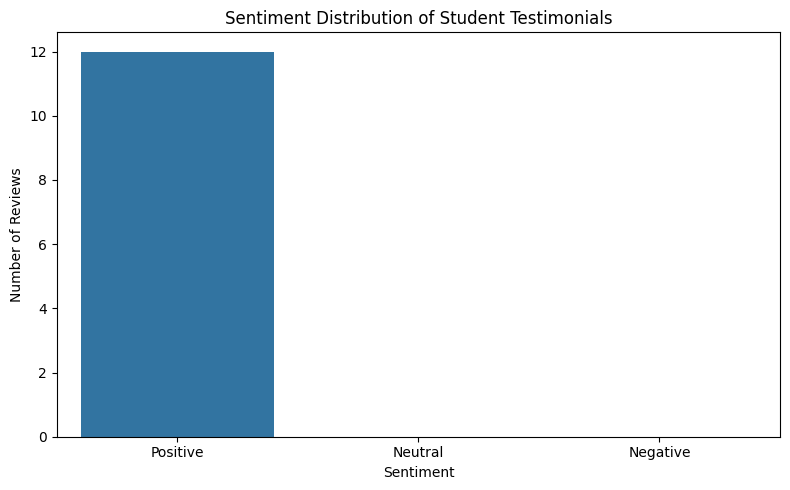

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Sentiment Distribution of Student Testimonials")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()